<a href="https://colab.research.google.com/github/laaljmarwa4038encg-sketch/DS-projet-F3-LAALJ_Marwa_LABRAHMI_Doha/blob/main/Projet_F3_Previsions_Inflation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projet F3 : Prévision de l'inflation

**Travail fait par:** -LABRAHMI Doha
                      -LAALJ Marwa

**Objectif :** étudier si le taux de chômage et le taux directeur aident à prévoir l'inflation américaine à un horizon de 12 mois.

**Tâche :** régression sur séries temporelles.

**Données :** CPIAUCSL (indice des prix), UNRATE (taux de chômage) et FEDFUNDS (taux directeur), fusionnées dans `dataset_F3_inflation.xlsx`.



**Problématique :** Le chômage et le taux directeur, associés à l'inflation passée, permettent-ils d'améliorer une prévision simple de l'inflation à 12 mois ?

## 2. Le jeu de données

Le projet utilise trois séries mensuelles provenant de la Federal Reserve Bank of St. Louis (FRED), fournies sous forme de fichiers CSV.

| Variable | Signification | Utilisation |
|---|---|---|
| `observation_date` | Date de l'observation | Index temporel |
| `CPIAUCSL` | Indice des prix à la consommation | Calcul de l'inflation |
| `UNRATE` | Taux de chômage américain | Variable explicative |
| `FEDFUNDS` | Taux effectif des fonds fédéraux | Variable explicative |
| `INFLATION_YOY` | Variation annuelle du CPI en % | Variable à prévoir |

Les trois séries sont fusionnées sur un calendrier mensuel complet avant le calcul de l'inflation. Cette étape est importante : une date absente ne doit pas décaler les retards (*lags*) ni l'horizon de prévision de 12 mois.


## 3. Première exploration

Avant la modélisation, on examine la structure du fichier, les types de colonnes, les valeurs manquantes et les statistiques descriptives.

In [ ]:
# Importation des bibliothèques nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Outils de préparation et de validation chronologique
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Modèles de régression à comparer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor

# Métriques et outils d'interprétation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# Fixer la graine aléatoire pour rendre les résultats reproductibles
np.random.seed(42)

# Définir un style commun pour les graphiques
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Lire les trois séries économiques originales
cpi = pd.read_csv("/content/drive/MyDrive/DS_Projet_F3_LABRAHMI_Doha_LAALJ_Marwa_FIN3/CPIAUCSL.csv", na_values=[".", ""])
unrate = pd.read_csv("/content/drive/MyDrive/DS_Projet_F3_LABRAHMI_Doha_LAALJ_Marwa_FIN3/UNRATE.csv", na_values=[".", ""])
fedfunds = pd.read_csv("/content/drive/MyDrive/DS_Projet_F3_LABRAHMI_Doha_LAALJ_Marwa_FIN3/FEDFUNDS.csv", na_values=[".", ""])

# Convertir les dates au format datetime
for serie in [cpi, unrate, fedfunds]:
    serie["observation_date"] = pd.to_datetime(serie["observation_date"])

# Placer les dates en index pour aligner correctement les séries
cpi = cpi.set_index("observation_date")
unrate = unrate.set_index("observation_date")
fedfunds = fedfunds.set_index("observation_date")

# Fusionner les séries en conservant toutes les dates disponibles
df = pd.concat([
    cpi["CPIAUCSL"],
    unrate["UNRATE"],
    fedfunds["FEDFUNDS"]
], axis=1)

# Reconstituer un calendrier mensuel complet
# Les mois réellement manquants restent présents avec des valeurs NaN
df = df.asfreq("MS")

# Calculer l'inflation annuelle en comparant le CPI au même mois de l'année précédente
df["INFLATION_YOY"] = (
    df["CPIAUCSL"].pct_change(periods=12, fill_method=None) * 100
)

# Remettre la date dans une colonne
df = df.reset_index()

# Trier les observations par ordre chronologique
df = df.sort_values("observation_date").reset_index(drop=True)

# Afficher les dimensions et les premières lignes du dataset
print("Dimensions :", df.shape)
display(df.head())


Dimensions : (958, 5)


,observation_date,CPIAUCSL,UNRATE,FEDFUNDS,INFLATION_YOY
0,1947-01-01,21.48,NaN,NaN,NaN
1,1947-02-01,21.62,NaN,NaN,NaN
2,1947-03-01,22.00,NaN,NaN,NaN
3,1947-04-01,22.00,NaN,NaN,NaN
4,1947-05-01,21.95,NaN,NaN,NaN


In [ ]:
# Afficher les types des colonnes et le nombre de valeurs non renseignées
df.info()

# Compter les valeurs manquantes dans chaque colonne
print("\\nValeurs manquantes par colonne :")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 958 entries, 0 to 957
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   observation_date  958 non-null    datetime64[ns]
 1   CPIAUCSL          956 non-null    float64       
 2   UNRATE            944 non-null    float64       
 3   FEDFUNDS          868 non-null    float64       
 4   INFLATION_YOY     944 non-null    float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 37.6 KB
\nValeurs manquantes par colonne :
observation_date     0
CPIAUCSL             2
UNRATE              14
FEDFUNDS            90
INFLATION_YOY       14
dtype: int64


In [ ]:
# Calculer les statistiques descriptives des variables numériques
# La fonction describe donne notamment la moyenne, l'écart-type et les quartiles
display(df.describe().round(2))

,observation_date,CPIAUCSL,UNRATE,FEDFUNDS,INFLATION_YOY
count,958,956.00,944.00,868.00,944.00
mean,1986-11-15 18:29:18.663883072,125.81,5.65,4.59,3.52
min,1947-01-01 00:00:00,21.48,2.50,0.05,-2.99
25%,1966-12-08 18:00:00,32.89,4.30,1.94,1.67
50%,1986-11-16 00:00:00,110.30,5.45,4.24,2.87
75%,2006-10-24 06:00:00,202.82,6.70,6.10,4.42
max,2026-10-01 00:00:00,336.30,14.80,19.10,14.59
std,NaN,91.04,1.70,3.52,2.86


## 4. Visualisation des données

Les graphiques permettent de comprendre les distributions, les évolutions historiques et les relations entre les indicateurs économiques.

### 4.1 Distribution des variables

Les histogrammes permettent de visualiser les valeurs les plus fréquentes et l'étendue de chaque indicateur.

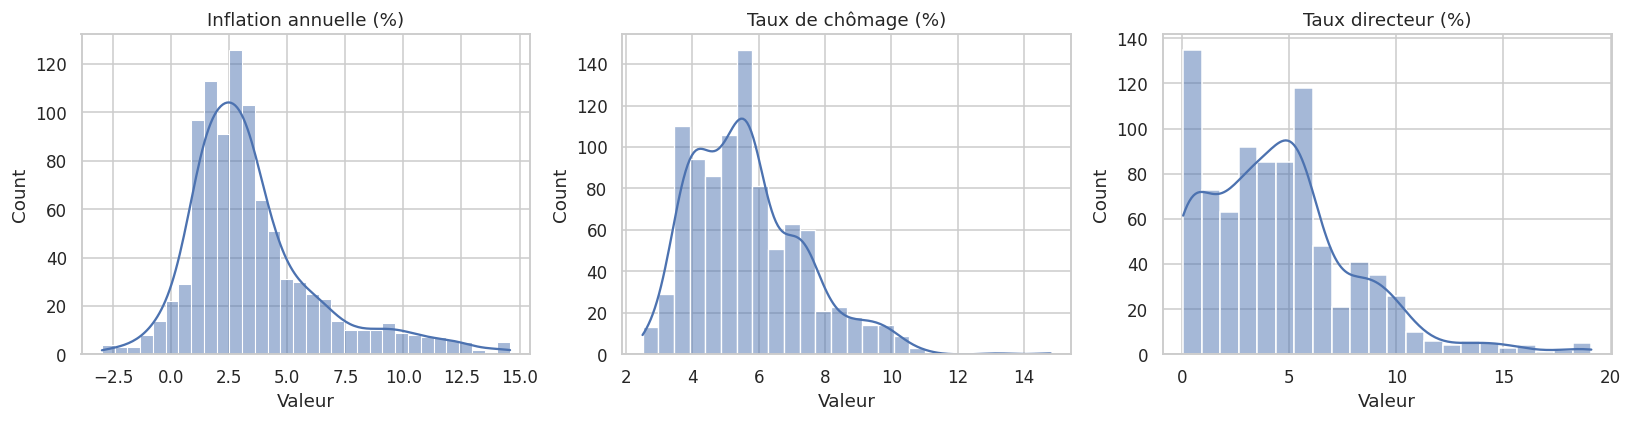

In [ ]:
# Choisir les trois variables économiques à examiner
variables = ["INFLATION_YOY", "UNRATE", "FEDFUNDS"]

# Définir les titres lisibles des graphiques
titres = [
    "Inflation annuelle (%)",
    "Taux de chômage (%)",
    "Taux directeur (%)"
]

# Créer une figure contenant trois histogrammes
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Tracer la distribution de chaque variable
for ax, var, titre in zip(axes, variables, titres):
    sns.histplot(data=df, x=var, kde=True, ax=ax)
    ax.set_title(titre)
    ax.set_xlabel("Valeur")

# Ajuster l'espacement et afficher les graphiques
plt.tight_layout()
plt.show()

### 4.2 Évolution des variables dans le temps

Les courbes chronologiques permettent de repérer les tendances, les cycles et les périodes de forte variation.

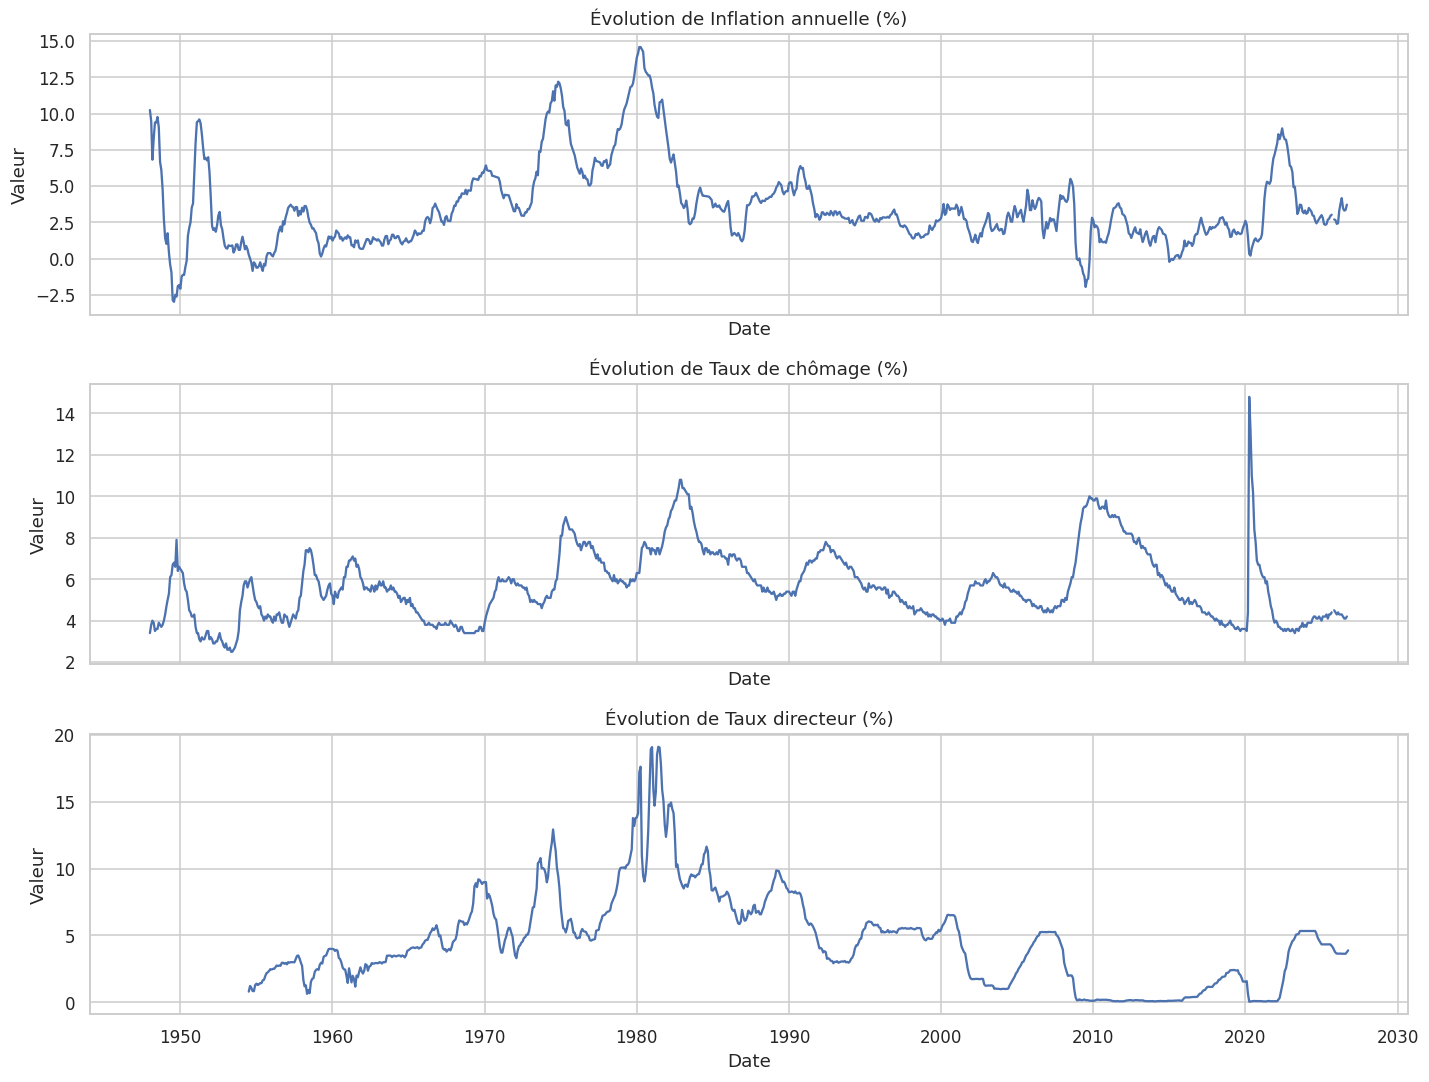

In [ ]:
# Créer trois graphiques empilés pour conserver une échelle propre à chaque variable
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

# Tracer chaque indicateur en fonction de la date
for ax, var, titre in zip(axes, variables, titres):
    ax.plot(df["observation_date"], df[var])
    ax.set_title(f"Évolution de {titre}")
    ax.set_ylabel("Valeur")
    ax.set_xlabel("Date")

# Ajuster la mise en page puis afficher
plt.tight_layout()
plt.show()

### 4.3 Relation entre deux variables

Les nuages de points donnent une première indication sur les relations entre l'inflation et les variables explicatives. Une association visuelle ne prouve pas une causalité.

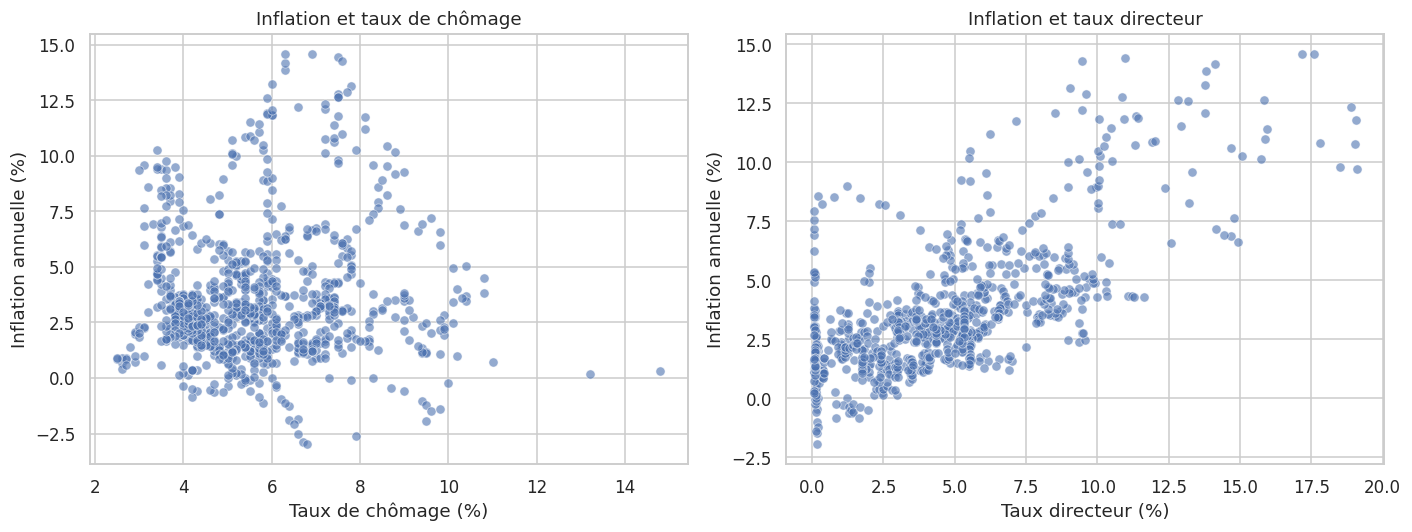

In [ ]:
# Créer deux graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Examiner la relation entre chômage et inflation
sns.scatterplot(data=df, x="UNRATE", y="INFLATION_YOY", alpha=0.6, ax=axes[0])
axes[0].set_title("Inflation et taux de chômage")
axes[0].set_xlabel("Taux de chômage (%)")
axes[0].set_ylabel("Inflation annuelle (%)")

# Examiner la relation entre taux directeur et inflation
sns.scatterplot(data=df, x="FEDFUNDS", y="INFLATION_YOY", alpha=0.6, ax=axes[1])
axes[1].set_title("Inflation et taux directeur")
axes[1].set_xlabel("Taux directeur (%)")
axes[1].set_ylabel("Inflation annuelle (%)")

# Ajuster et afficher les graphiques
plt.tight_layout()
plt.show()

### 4.4 Boîtes à moustaches et corrélations

Les boîtes à moustaches résument la distribution et les valeurs extrêmes. La matrice de corrélation mesure les associations linéaires entre les variables.

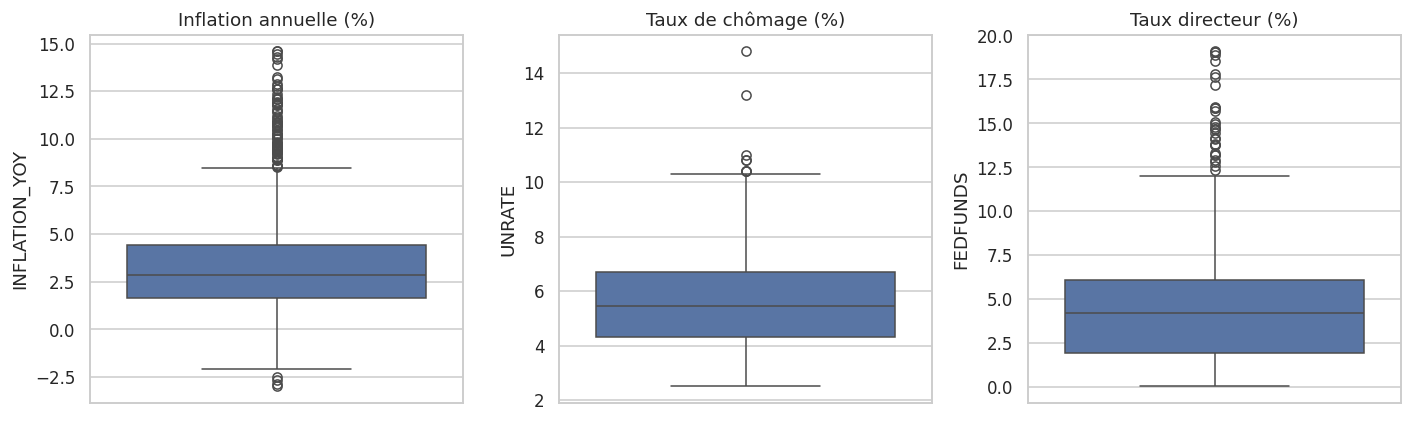

In [ ]:
# Créer une boîte à moustaches pour chacune des trois variables
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, var, titre in zip(axes, variables, titres):
    # Afficher la médiane, les quartiles et les observations éloignées
    sns.boxplot(y=df[var], ax=ax)
    ax.set_title(titre)

plt.tight_layout()
plt.show()

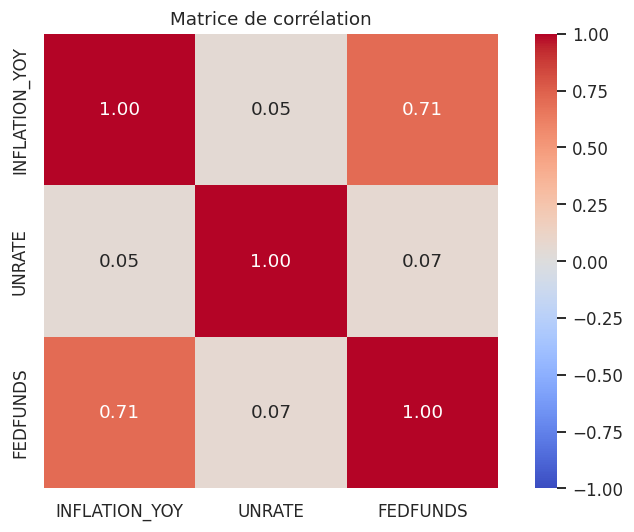

In [ ]:
# Calculer les corrélations linéaires entre les trois indicateurs
corr = df[variables].corr()

# Afficher les coefficients dans une carte de chaleur
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    corr,
    annot=True,       # Afficher la valeur de chaque corrélation
    fmt=".2f",        # Limiter l'affichage à deux décimales
    cmap="coolwarm",  # Couleurs opposées pour les corrélations positives et négatives
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax
)
ax.set_title("Matrice de corrélation")
plt.tight_layout()
plt.show()

**Lecture.** Commenter les périodes de hausse ou de baisse et les relations observées. Les corrélations contemporaines ne suffisent pas à établir une capacité de prévision : les modèles utiliseront également des valeurs passées.

## 5. Préparation des données

La préparation doit respecter le temps : une observation à la date *t* ne peut utiliser que des informations disponibles à cette date pour prévoir l'inflation à *t+12*.

- Calculer la cible à 12 mois.
- Créer des variables retardées (*lags*) pour représenter l'historique.
- Construire les variables explicatives `X` et la cible `y`.
- Séparer entraînement et test dans l'ordre chronologique.
- Apprendre les transformations uniquement sur les données d'entraînement.

> **Précaution :** le fichier historique FRED peut contenir des données révisées et les dates de publication ne sont pas modélisées ici. Il s'agit donc d'une expérience pédagogique de prévision, pas d'un système de prévision en temps réel sans biais de disponibilité.

**Point de vigilance sur le calendrier.** Les séries peuvent comporter des mois manquants. Le calendrier mensuel complet est donc conservé jusqu'à la création de la cible et des retards. Les lignes incomplètes sont supprimées seulement ensuite, afin que `shift(12)` représente bien 12 mois calendaires et non 12 lignes disponibles.


In [ ]:
# Copier les données pour conserver le dataset initial intact
df_model = df.copy()

# Trier les observations par date sans supprimer les mois incomplets
# Il faut conserver le calendrier mensuel complet avant de créer les retards
df_model = df_model.sort_values("observation_date").reset_index(drop=True)

# Vérifier le nombre d'observations et les valeurs manquantes
print("Nombre total de mois :", len(df_model))
print("\\nValeurs manquantes par colonne :")
print(df_model[["CPIAUCSL", "UNRATE", "FEDFUNDS", "INFLATION_YOY"]].isna().sum())


Nombre total de mois : 958
\nValeurs manquantes par colonne :
CPIAUCSL          2
UNRATE           14
FEDFUNDS         90
INFLATION_YOY    14
dtype: int64


In [ ]:
# Créer la cible : inflation annuelle observée 12 mois après la date de départ
# shift(-12) ramène la valeur future de 12 lignes vers l'observation actuelle
df_model["TARGET_INFLATION_12M"] = df_model["INFLATION_YOY"].shift(-12)

# Afficher quelques lignes pour vérifier le décalage de la cible
display(df_model[[
    "observation_date", "INFLATION_YOY", "TARGET_INFLATION_12M"
]].head(15))

,observation_date,INFLATION_YOY,TARGET_INFLATION_12M
0,1947-01-01,NaN,10.242086
1,1947-02-01,NaN,9.481961
2,1947-03-01,NaN,6.818182
3,1947-04-01,NaN,8.272727
4,1947-05-01,NaN,9.384966
5,1947-06-01,NaN,9.375000
6,1947-07-01,NaN,9.761583
7,1947-08-01,NaN,9.062500
8,1947-09-01,NaN,6.654991
9,1947-10-01,NaN,6.110869


In [ ]:
# Définir les indicateurs dont on souhaite utiliser l'historique
variables_base = ["INFLATION_YOY", "UNRATE", "FEDFUNDS"]

# Créer les retards de 1, 3, 6 et 12 mois pour chaque indicateur
for variable in variables_base:
    for lag in [1, 3, 6, 12]:
        # La nouvelle colonne contient la valeur observée 'lag' mois auparavant
        df_model[f"{variable}_LAG_{lag}"] = df_model[variable].shift(lag)

# Afficher les colonnes créées
print(df_model.columns.tolist())

['observation_date', 'CPIAUCSL', 'UNRATE', 'FEDFUNDS', 'INFLATION_YOY', 'TARGET_INFLATION_12M', 'INFLATION_YOY_LAG_1', 'INFLATION_YOY_LAG_3', 'INFLATION_YOY_LAG_6', 'INFLATION_YOY_LAG_12', 'UNRATE_LAG_1', 'UNRATE_LAG_3', 'UNRATE_LAG_6', 'UNRATE_LAG_12', 'FEDFUNDS_LAG_1', 'FEDFUNDS_LAG_3', 'FEDFUNDS_LAG_6', 'FEDFUNDS_LAG_12']


In [ ]:
# Conserver les valeurs du mois courant comme variables explicatives
features = variables_base.copy()

# Ajouter les colonnes retardées à la liste des variables explicatives
for variable in variables_base:
    for lag in [1, 3, 6, 12]:
        features.append(f"{variable}_LAG_{lag}")

# Définir le nom de la variable cible
target = "TARGET_INFLATION_12M"

# Retirer les lignes incomplètes seulement après la création de la cible et des retards
# Les décalages correspondent ainsi toujours à de vrais mois calendaires
data = df_model.dropna(subset=features + [target]).copy()

# Construire X (variables explicatives) et y (inflation à prévoir)
X = data[features]
y = data[target]

# Afficher les dimensions des données préparées
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
display(X.head())


Dimensions de X : (842, 15)
Dimensions de y : (842,)


,INFLATION_YOY,UNRATE,FEDFUNDS,INFLATION_YOY_LAG_1,INFLATION_YOY_LAG_3,INFLATION_YOY_LAG_6,INFLATION_YOY_LAG_12,UNRATE_LAG_1,UNRATE_LAG_3,UNRATE_LAG_6,UNRATE_LAG_12,FEDFUNDS_LAG_1,FEDFUNDS_LAG_3,FEDFUNDS_LAG_6,FEDFUNDS_LAG_12
102,-0.372301,4.0,1.68,-0.853749,-0.260611,-0.631032,0.261292,4.2,4.7,4.9,5.8,1.64,1.43,1.39,0.80
103,-0.484171,4.2,1.96,-0.372301,-0.594133,-0.629863,0.000000,4.0,4.3,4.7,6.0,1.68,1.43,1.29,1.22
104,0.149198,4.1,2.18,-0.484171,-0.853749,-0.519866,-0.297508,4.2,4.2,4.6,6.1,1.96,1.64,1.35,1.07
105,0.374251,4.3,2.24,0.149198,-0.372301,-0.260611,-0.853432,4.1,4.0,4.7,5.7,2.18,1.68,1.43,0.85
106,0.373413,4.2,2.35,0.374251,-0.484171,-0.594133,-0.260708,4.3,4.2,4.3,5.3,2.24,1.96,1.43,0.83


In [ ]:
# Calculer la position correspondant à 80 % des observations utilisables
split = int(len(data) * 0.80)

# Retirer 12 observations avant le test pour limiter le chevauchement
# des horizons de cible entre l'entraînement et le test
train_end = split - 12

# Construire les ensembles en respectant l'ordre chronologique
X_train = X.iloc[:train_end].copy()
X_test = X.iloc[split:].copy()
y_train = y.iloc[:train_end].copy()
y_test = y.iloc[split:].copy()

# Afficher les tailles des deux ensembles
print("Taille de l'entraînement :", len(X_train))
print("Taille du test :", len(X_test))

# Afficher les dates couvertes par chaque ensemble
print("Période d'entraînement :", data["observation_date"].iloc[0],
      "à", data["observation_date"].iloc[train_end - 1])
print("Période de test :", data["observation_date"].iloc[split],
      "à", data["observation_date"].iloc[-1])

Taille de l'entraînement : 661
Taille du test : 169
Période d'entraînement : 1955-07-01 00:00:00 à 2010-07-01 00:00:00
Période de test : 2011-08-01 00:00:00 à 2025-09-01 00:00:00


**Remarque sur le découpage.** Le retrait de 12 observations crée un intervalle de sécurité entre les origines de prévision d'entraînement et de test. La validation croisée utilisera également `gap=12`. Pour une étude économétrique plus avancée, il faudrait aussi tenir compte des dates de publication et des révisions des séries.

## 6. Entraînement et comparaison des modèles

Nous comparons trois approches :

1. **Référence de persistance :** suppose que l'inflation dans 12 mois sera égale à l'inflation connue aujourd'hui.
2. **Ridge :** régression linéaire régularisée, avec standardisation des variables.
3. **Gradient Boosting :** ensemble d'arbres qui apprend progressivement à corriger les erreurs.

Le critère de comparaison principal est le RMSE : plus il est faible, meilleures sont les prévisions.

In [ ]:
# Définir une référence simple : la prévision reprend l'inflation actuelle
# Cette classe respecte l'interface scikit-learn pour pouvoir être validée en CV
from sklearn.base import BaseEstimator, RegressorMixin

class PersistenceBaseline(BaseEstimator, RegressorMixin):
    def fit(self, X, y):
        # Aucun paramètre n'est appris pour cette règle de référence
        return self

    def predict(self, X):
        # Prévoir à 12 mois la même inflation que celle observée au départ
        return X["INFLATION_YOY"].to_numpy()

In [ ]:
# Construire un pipeline Ridge :
# 1) remplacer les valeurs manquantes éventuelles par la médiane ;
# 2) standardiser les variables ;
# 3) entraîner une régression Ridge.
ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("modele", Ridge(alpha=1.0))
])

# Construire un pipeline Gradient Boosting :
# l'imputation est conservée par sécurité, mais la standardisation n'est pas nécessaire
gb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("modele", GradientBoostingRegressor(
        n_estimators=100,     # Nombre d'arbres successifs
        learning_rate=0.05,   # Contribution de chaque nouvel arbre
        max_depth=2,          # Profondeur limitée pour contrôler la complexité
        random_state=42       # Résultats reproductibles
    ))
])

# Rassembler les modèles dans un dictionnaire pour faciliter leur comparaison
modeles = {
    "Référence (persistance)": PersistenceBaseline(),
    "Ridge Regression": ridge_pipeline,
    "Gradient Boosting": gb_pipeline
}

In [ ]:
# Définir une validation croisée adaptée aux séries temporelles
# gap=12 écarte 12 observations entre entraînement et validation à chaque pli
validation = TimeSeriesSplit(n_splits=5, gap=12)

# Préparer une liste qui recevra les scores de chaque modèle
resultats_cv = []

# Évaluer successivement chaque modèle avec la même validation chronologique
for nom, modele in modeles.items():

    # Le score scikit-learn est négatif : on change son signe pour obtenir un RMSE positif
    scores = cross_val_score(
        modele,
        X_train,
        y_train,
        cv=validation,
        scoring="neg_root_mean_squared_error"
    )

    # Enregistrer le RMSE moyen et son écart-type entre les plis
    resultats_cv.append({
        "Modèle": nom,
        "RMSE moyen": -scores.mean(),
        "Écart-type RMSE": scores.std()
    })

# Construire un tableau et classer les modèles du meilleur au moins bon RMSE
tableau = pd.DataFrame(resultats_cv).sort_values("RMSE moyen")

# Afficher les résultats arrondis
display(tableau.round(3))

,Modèle,RMSE moyen,Écart-type RMSE
0,Référence (persistance),1.996,0.754
1,Ridge Regression,2.916,1.253
2,Gradient Boosting,3.363,1.254


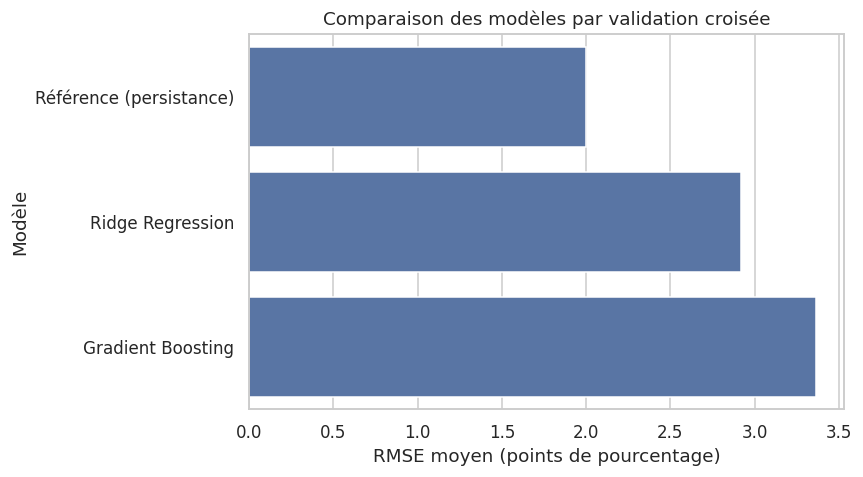

In [ ]:
# Représenter les RMSE moyens pour comparer visuellement les modèles
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.barplot(
    data=tableau,
    x="RMSE moyen",
    y="Modèle",
    ax=ax
)

# Ajouter un titre et préciser l'unité de l'erreur
ax.set_title("Comparaison des modèles par validation croisée")
ax.set_xlabel("RMSE moyen (points de pourcentage)")
ax.set_ylabel("Modèle")

plt.tight_layout()
plt.show()

**Lecture.** Le modèle ayant le RMSE moyen le plus faible est le plus performant sur les plis de validation. L'écart-type renseigne sur la variabilité des scores. Il faut vérifier si les modèles de Machine Learning font mieux que la référence de persistance.

## 7. Évaluation finale sur le jeu de test

Le modèle est sélectionné à partir de la validation croisée, puis réentraîné sur tout l'ensemble d'entraînement. Le jeu de test est utilisé une seule fois pour estimer la performance sur une période ultérieure.

In [ ]:
# Identifier le modèle ayant le plus petit RMSE moyen en validation croisée
meilleur_nom = tableau.iloc[0]["Modèle"]
meilleur_modele = modeles[meilleur_nom]

# Entraîner le modèle sélectionné sur l'ensemble d'entraînement
meilleur_modele.fit(X_train, y_train)

# Produire les prévisions sur la période de test
y_pred = meilleur_modele.predict(X_test)

# Calculer les métriques adaptées à un problème de régression
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Afficher le modèle retenu et ses performances
print("Meilleur modèle :", meilleur_nom)
print(f"RMSE sur le test : {rmse:.3f}")
print(f"MAE sur le test  : {mae:.3f}")
print(f"R² sur le test   : {r2:.3f}")

Meilleur modèle : Référence (persistance)
RMSE sur le test : 2.084
MAE sur le test  : 1.470
R² sur le test   : -0.095


In [ ]:
# Calculer les prévisions des trois modèles sur le jeu de test
predictions_test = {}

for nom, modele in modeles.items():
    # Entraîner chaque modèle sur les données d'entraînement
    modele.fit(X_train, y_train)

    # Enregistrer les prévisions réalisées sur les données de test
    predictions_test[nom] = modele.predict(X_test)

# Calculer les métriques pour chaque modèle
comparaison_test = []

for nom, pred in predictions_test.items():
    comparaison_test.append({
        "Modèle": nom,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
        "R²": r2_score(y_test, pred)
    })

# Trier le tableau selon le RMSE croissant
tableau_test = pd.DataFrame(comparaison_test).sort_values("RMSE")

display(tableau_test.round(3))

,Modèle,RMSE,MAE,R²
0,Référence (persistance),2.084,1.470,-0.095
2,Gradient Boosting,2.557,1.771,-0.649
1,Ridge Regression,2.836,2.004,-1.029


### 7.1 Inflation réelle et inflation prévue

Le graphique compare les valeurs réellement observées 12 mois après chaque date de départ aux prévisions des modèles.

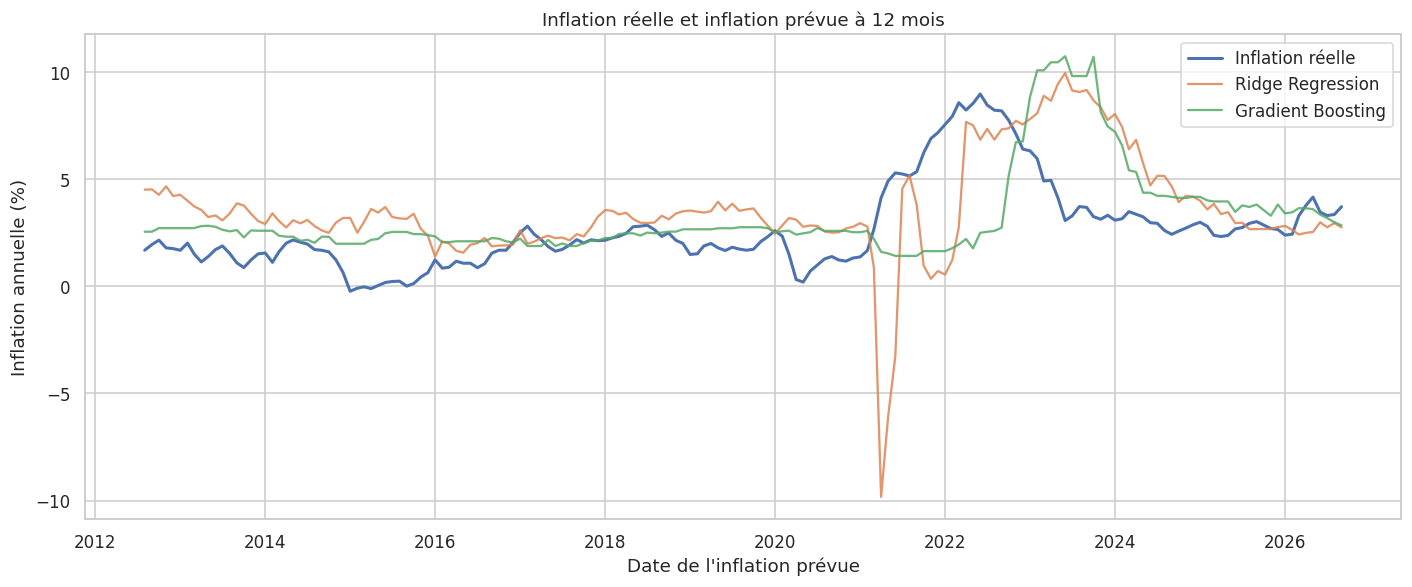

In [ ]:
# Récupérer les dates auxquelles les valeurs cibles sont effectivement observées
dates_test = data["observation_date"].iloc[split:].reset_index(drop=True) + pd.DateOffset(months=12)

# Tracer l'inflation réelle et les prévisions des modèles
fig, ax = plt.subplots(figsize=(13, 5.5))

ax.plot(dates_test, y_test.to_numpy(), label="Inflation réelle", linewidth=2)

# Ajouter les prévisions de Ridge et Gradient Boosting
for nom in ["Ridge Regression", "Gradient Boosting"]:
    ax.plot(dates_test, predictions_test[nom], label=nom, alpha=0.85)

ax.set_title("Inflation réelle et inflation prévue à 12 mois")
ax.set_xlabel("Date de l'inflation prévue")
ax.set_ylabel("Inflation annuelle (%)")
ax.legend()
plt.tight_layout()
plt.show()

### 7.2 Analyse des erreurs

Les résidus sont les différences entre les valeurs réelles et les valeurs prévues. Une erreur positive signifie que le modèle a sous-estimé l'inflation.

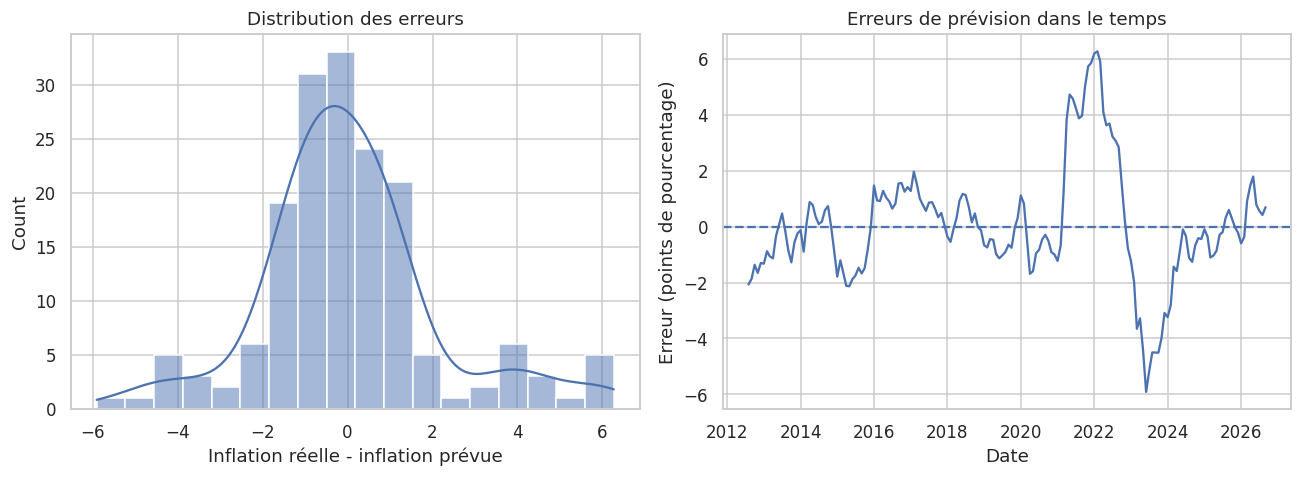

In [ ]:
# Calculer les résidus du modèle sélectionné
residus = y_test.to_numpy() - y_pred

# Afficher leur distribution sous forme d'histogramme
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(residus, kde=True, ax=axes[0])
axes[0].set_title("Distribution des erreurs")
axes[0].set_xlabel("Inflation réelle - inflation prévue")

# Vérifier si les erreurs évoluent au cours du temps
axes[1].plot(dates_test, residus)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Erreurs de prévision dans le temps")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Erreur (points de pourcentage)")

plt.tight_layout()
plt.show()

### 7.3 Courbe d'apprentissage

La courbe d'apprentissage montre l'évolution de l'erreur lorsque le modèle reçoit davantage d'observations d'entraînement. Pour une régression, nous utilisons le RMSE plutôt que l'exactitude.

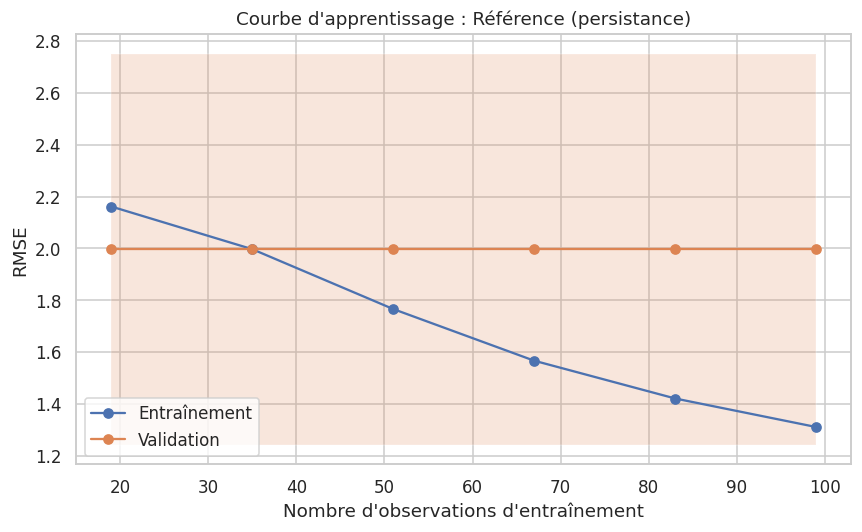

In [ ]:
# Calculer les tailles d'échantillon et les scores d'apprentissage/validation
tailles, scores_train, scores_val = learning_curve(
    meilleur_modele,
    X_train,
    y_train,
    train_sizes=np.linspace(0.2, 1.0, 6),
    cv=validation,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Convertir les scores négatifs en RMSE positifs
rmse_train = -scores_train
rmse_val = -scores_val

# Calculer les moyennes et écarts-types pour chaque taille d'échantillon
moy_train = rmse_train.mean(axis=1)
std_train = rmse_train.std(axis=1)
moy_val = rmse_val.mean(axis=1)
std_val = rmse_val.std(axis=1)

# Tracer les courbes d'apprentissage avec les zones de variabilité
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(tailles, moy_train, "o-", label="Entraînement")
ax.fill_between(tailles, moy_train - std_train, moy_train + std_train, alpha=0.2)

ax.plot(tailles, moy_val, "o-", label="Validation")
ax.fill_between(tailles, moy_val - std_val, moy_val + std_val, alpha=0.2)

ax.set_xlabel("Nombre d'observations d'entraînement")
ax.set_ylabel("RMSE")
ax.set_title(f"Courbe d'apprentissage : {meilleur_nom}")
ax.legend()

plt.tight_layout()
plt.show()

**Lecture.** Pour le RMSE, une valeur plus faible est préférable. Un écart important entre l'erreur d'entraînement et celle de validation peut signaler du surapprentissage. Des erreurs élevées et proches peuvent signaler un modèle trop simple ou des données peu prédictives.

## 8. Interprétation du modèle

L'interprétation permet de déterminer quelles variables contribuent le plus aux prévisions. Une importance élevée ne signifie pas qu'une variable cause l'inflation.

### 8.1 Importance des variables par permutation

On mesure la baisse de performance lorsque les valeurs d'une variable sont mélangées. Une baisse importante indique que le modèle utilise cette information.

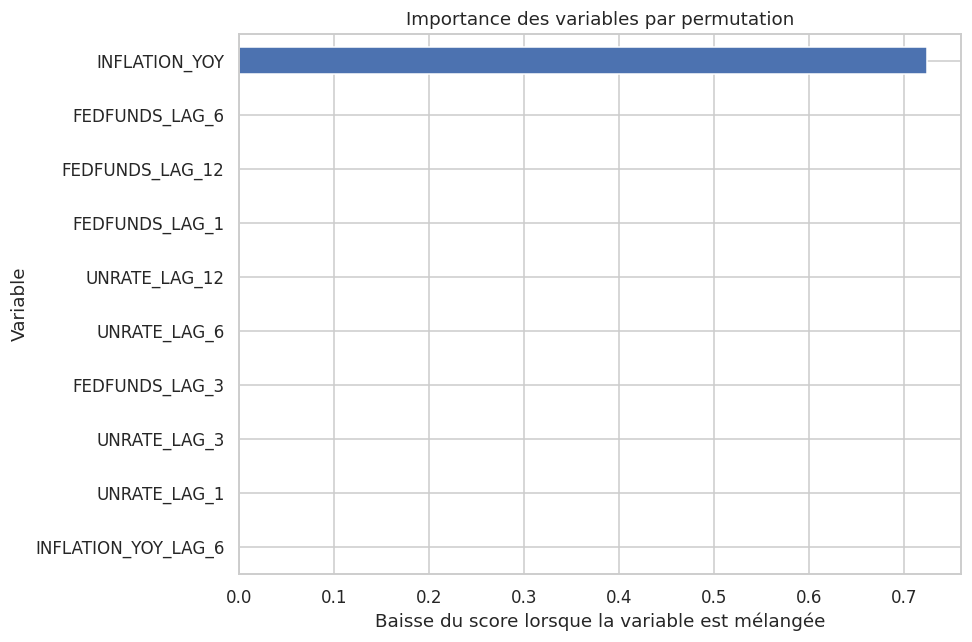

In [ ]:
# Calculer l'importance par permutation sur le jeu de test
# Le score utilisé est le RMSE négatif : une forte baisse de score indique une variable utile
importance_perm = permutation_importance(
    meilleur_modele,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="neg_root_mean_squared_error"
)

# Construire une série associant chaque variable à son importance moyenne
importances = pd.Series(
    importance_perm.importances_mean,
    index=features
).sort_values()

# Tracer les dix variables les plus importantes
fig, ax = plt.subplots(figsize=(9, 6))
importances.tail(10).plot.barh(ax=ax)

ax.set_title("Importance des variables par permutation")
ax.set_xlabel("Baisse du score lorsque la variable est mélangée")
ax.set_ylabel("Variable")

plt.tight_layout()
plt.show()

### 8.2 Dépendance partielle

La dépendance partielle montre comment la prédiction moyenne du modèle évolue lorsque l'on fait varier une variable, en moyennant sur les autres variables. Cette visualisation décrit le comportement du modèle, pas une relation causale.

In [ ]:
# Choisir les variables économiques actuelles à examiner
variables_a_etudier = ["UNRATE", "FEDFUNDS"]

# Tracer les dépendances partielles si le modèle sélectionné le permet
# Le modèle de persistance ne supporte pas l'analyse de dépendance partielle
if "Référence" in meilleur_nom:
    print(f"La dépendance partielle n'est pas disponible pour le modèle de base : {meilleur_nom}.")
    print("Vous pouvez essayer d'analyser le modèle 'Gradient Boosting' à la place en utilisant : modeles['Gradient Boosting']")
else:
    fig, ax = plt.subplots(figsize=(10, 4))
    PartialDependenceDisplay.from_estimator(
        meilleur_modele,
        X_train,
        features=variables_a_etudier,
        ax=ax
    )
    plt.suptitle("Dépendance partielle des prévisions")
    plt.tight_layout()
    plt.show()

La dépendance partielle n'est pas disponible pour le modèle de base : Référence (persistance).
Vous pouvez essayer d'analyser le modèle 'Gradient Boosting' à la place en utilisant : modeles['Gradient Boosting']


## 9. Prédire une nouvelle observation

Pour produire une prévision à partir des dernières données disponibles, on utilise la dernière ligne qui contient les variables explicatives et leurs retards. La prédiction correspond à l'inflation annuelle attendue 12 mois après cette date.

> Cette prévision pédagogique suppose que les indicateurs du mois courant sont déjà disponibles. En pratique, il faudrait utiliser les dernières données publiées à la date de prévision.

In [ ]:
# Reconstituer les variables explicatives de la dernière date disponible
# La cible future peut être absente : ce n'est pas gênant pour une nouvelle prédiction
derniere_observation = df_model.dropna(subset=features).iloc[[-1]]
nouveau_X = derniere_observation[features]

# Afficher la date de départ de la prévision
date_depart = derniere_observation["observation_date"].iloc[0]
print("Date de départ :", date_depart.date())

# Réentraîner le modèle sélectionné sur toutes les observations étiquetées disponibles
meilleur_modele.fit(X, y)

# Prévoir l'inflation annuelle 12 mois après la date de départ
prevision = meilleur_modele.predict(nouveau_X)[0]

# Afficher la date cible et la valeur prévue
date_prevue = date_depart + pd.DateOffset(months=12)
print("Date de prévision :", date_prevue.date())
print(f"Inflation annuelle prévue : {prevision:.2f} %")

Date de départ : 2026-09-01
Date de prévision : 2027-09-01
Inflation annuelle prévue : 3.72 %
